In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
# Configure matplotlib to output both SVG (vector)
%config InlineBackend.figure_formats = ['svg']

#### Building the dataset
A dictionary-based dataset will be constructed using the .dat files output from the simulation. Important things to consider for users: the algorithm relies on .dat files following a specific naming convention in `obs_K_{k}_r0_{r0}_seed_{seed}.dat`.

The initial dictionary can be accessed using the folder name key e.g.:

`dat_files_dict['fd_push_full_rod_dats']`

A specific data set can be retrieved using:

`dat_files_dict['fd_push_full_rod_dats'][(k,r0,seed)]`

At any time, use `.keys()` to identify the available data fields at any level in the dictionary. All dictionaries follow a similar organisation.

In [4]:
#### READ SIMULATION OUTPUTS AND APPENDS THEM TO A DICTIONARY OF DATAFRAMES
INPUT_FOLDER = 'force-extension/fextensions_results'

import re

def extract_parameters_from_filename(filename):
    """
    Extract K, r0, and seed from filename.
    Adjust the regex pattern to match your naming convention.
    
    Common patterns might be:
    - K_<value>_r0_<value>_seed_<value>.dat
    - output_K<value>_r0<value>_seed<value>.dat
    """
    # Try to extract K, r0, and seed using regex
    # Adjust this pattern based on your actual naming convention
    pattern = r'K[_]?(\d+(?:\.\d+)?)[_]?.*r0[_]?(\d+(?:\.\d+)?)[_]?.*seed[_]?(\d+)'
    
    match = re.search(pattern, filename, re.IGNORECASE)
    if match:
        K = float(match.group(1))
        r0 = float(match.group(2))
        seed = int(match.group(3))
        return K, r0, seed
    
    # If pattern doesn't match, return None
    return None

# Dictionary to store data from each subfolder
dat_files_dict = {}

# Iterate through subfolders using scandir
for subfolder_entry in os.scandir(INPUT_FOLDER):
    if subfolder_entry.is_dir():
        subfolder_name = subfolder_entry.name
        dat_files_dict[subfolder_name] = {}
        
        # Iterate through files in the subfolder using scandir
        for file_entry in os.scandir(subfolder_entry.path):
            if file_entry.is_file() and file_entry.name.endswith('.dat'):
                try:
                    # Extract parameters from filename
                    params = extract_parameters_from_filename(file_entry.name)
                    
                    if params:
                        K, r0, seed = params
                        
                        # Read the .dat file
                        data = pd.read_csv(file_entry.path, sep='\s+', header=None)
                        
                        # Store with (K, r0, seed) as key
                        dat_files_dict[subfolder_name][(K, r0, seed)] = {
                            'filename': file_entry.name,
                            'data': data,
                            'K': K,
                            'r0': r0,
                            'seed': seed
                        }
                        #print(f"Loaded: {subfolder_name}/{file_entry.name} -> K={K}, r0={r0}, seed={seed}")
                    else:
                        print(f"Warning: Could not extract parameters from {file_entry.name}")
                    
                except Exception as e:
                    print(f"Error reading {file_entry.path}: {e}")
        
        # Remove empty subfolder entries
        if len(dat_files_dict[subfolder_name]) == 0:
            del dat_files_dict[subfolder_name]

# Summary
print(f"\n{'='*60}")
print(f"Summary: Found {len(dat_files_dict)} subfolders with .dat files")
print(f"{'='*60}")
for subfolder, files in dat_files_dict.items():
    print(f"{subfolder}: {len(files)} file(s)")
    # Show example parameters
    if files:
        example_key = list(files.keys())[0]
        print(f"  Example access: dat_files_dict['{subfolder}'][{example_key}]")
print(f"{'='*60}")


Summary: Found 8 subfolders with .dat files
fd_push_1qrt_rod_dats: 119 file(s)
  Example access: dat_files_dict['fd_push_1qrt_rod_dats'][(25.0, 30.0, 4)]
fd_pull_full_rod_dats: 370 file(s)
  Example access: dat_files_dict['fd_pull_full_rod_dats'][(25.0, 28.0, 2)]
fd_push_half_rod_dats: 120 file(s)
  Example access: dat_files_dict['fd_push_half_rod_dats'][(25.0, 30.0, 4)]
fd_pull_3qrt_rod_dats: 150 file(s)
  Example access: dat_files_dict['fd_pull_3qrt_rod_dats'][(25.0, 28.0, 2)]
fd_pull_half_rod_dats: 150 file(s)
  Example access: dat_files_dict['fd_pull_half_rod_dats'][(25.0, 28.0, 2)]
fd_push_full_rod_dats: 240 file(s)
  Example access: dat_files_dict['fd_push_full_rod_dats'][(15.0, 26.0, 4)]
fd_pull_1qrt_rod_dats: 150 file(s)
  Example access: dat_files_dict['fd_pull_1qrt_rod_dats'][(25.0, 28.0, 2)]
fd_push_3qrt_rod_dats: 120 file(s)
  Example access: dat_files_dict['fd_push_3qrt_rod_dats'][(15.0, 26.0, 4)]


In [6]:
#### TESTING OUT DICTIONARY CONTENTS AND ACCESSIBILITY
print(dat_files_dict.keys())
test = dat_files_dict['fd_push_full_rod_dats'][(15.0, 10.0, 1)]
print(test.keys())

dict_keys(['fd_push_1qrt_rod_dats', 'fd_pull_full_rod_dats', 'fd_push_half_rod_dats', 'fd_pull_3qrt_rod_dats', 'fd_pull_half_rod_dats', 'fd_push_full_rod_dats', 'fd_pull_1qrt_rod_dats', 'fd_push_3qrt_rod_dats'])
dict_keys(['filename', 'data', 'K', 'r0', 'seed'])


#### Calculating steady state regions via manual cutoff

In [7]:
CUTOFF = 2.5e7  # 2,500,000

# Create new dictionary for steady-state filtered data
ss_dat_files_dict = {}

# Iterate through all subfolders
for subfolder_name, files_dict in dat_files_dict.items():
    ss_dat_files_dict[subfolder_name] = {}
    
    # Iterate through all (K, r0, seed) combinations
    for (K, r0, seed), file_info in files_dict.items():
        df = file_info['data']
        
        # Apply cutoff filter (assuming first column is step)
        # Adjust column index if your step column is different
        df_filtered = df[df.iloc[:, 0] >= CUTOFF].reset_index(drop=True)
        
        # Store filtered data with same structure
        ss_dat_files_dict[subfolder_name][(K, r0, seed)] = {
            'filename': file_info['filename'],
            'data': df_filtered,
            'K': K,
            'r0': r0,
            'seed': seed
        }
        
        #print(f"Filtered {subfolder_name} (K={K}, r0={r0}, seed={seed}): {len(df)} -> {len(df_filtered)} rows")

# Summary
print(f"\n{'='*60}")
print(f"Cutoff filtering complete!")
print(f"Applied cutoff: step >= {CUTOFF}")
print(f"Processed {sum(len(files) for files in ss_dat_files_dict.values())} datasets")
print(f"{'='*60}")


Cutoff filtering complete!
Applied cutoff: step >= 25000000.0
Processed 1419 datasets


#### Computing statistics for each simulation

In [8]:
# Dictionary to store statistics for each simulation
stats_dict = {}

# Column indices (adjust based on your .dat file structure)
# Assuming columns are: [step, dist, force_mag, hbond, ...]
COL_STEP = 0
COL_DIST = 1
COL_FORCE_MAG = 2
COL_HBOND = 3

# Iterate through all subfolders
for subfolder_name, files_dict in ss_dat_files_dict.items():
    stats_dict[subfolder_name] = {}
    
    # Iterate through all (K, r0, seed) combinations
    for (K, r0, seed), file_info in files_dict.items():
        df = file_info['data']
        
        if len(df) == 0:
            print(f"Warning: Empty dataframe for {subfolder_name} (K={K}, r0={r0}, seed={seed})")
            continue
        
        # Extract columns as numpy arrays
        dist = df.iloc[:, COL_DIST].to_numpy()
        force_mag = df.iloc[:, COL_FORCE_MAG].to_numpy()
        hbond = df.iloc[:, COL_HBOND].to_numpy()
        
        # Calculate signed force: +|F| if dist > r0, -|F| if dist < r0
        signed_force = np.sign(dist - r0) * force_mag
        
        # Compute statistics
        stats_dict[subfolder_name][(K, r0, seed)] = {
            'K': K,
            'r0': r0,
            'seed': seed,
            'filename': file_info['filename'],
            
            # Signed force statistics
            'F_mean': signed_force.mean(),
            'F_std': signed_force.std(ddof=0),
            
            # Force magnitude statistics
            'force_mag_mean': force_mag.mean(),
            'force_mag_std': force_mag.std(ddof=0),
            
            # Distance statistics
            'dist_mean': dist.mean(),
            'dist_std': dist.std(ddof=0),
            
            # Hydrogen bond statistics
            'hbond_mean': hbond.mean(),
            'hbond_std': hbond.std(ddof=0),
            
            # Additional info
            'n_samples': len(df)
        }
        
        #print(f"Computed stats for {subfolder_name} (K={K}, r0={r0}, seed={seed}): {len(df)} samples")

# Summary
print(f"\n{'='*60}")
print(f"Statistics computation complete!")
print(f"Processed {sum(len(files) for files in stats_dict.values())} datasets")
print(f"{'='*60}")


Statistics computation complete!
Processed 1269 datasets


In [9]:
#### SET GLOBAL RC PARAMS
plt.rcParams.update({
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 8,
    "ytick.major.size": 8,
    "font.size": 14,
    "axes.labelsize": 14,
})

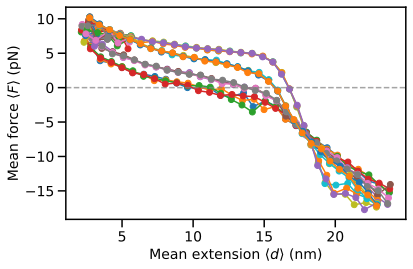

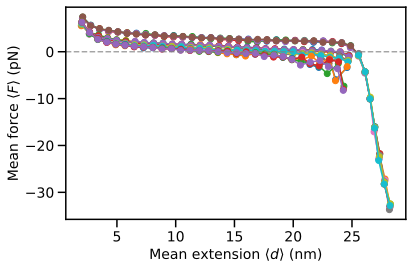

In [10]:
from collections import defaultdict
import numpy as np

# Unit conversion factors
DIST_CONVERSION = 0.8   # to nm
FORCE_CONVERSION = 48.6 # to pN

def plot_force_extension(stats_dict, design_keyword=None, figsize=(6, 4), show_legend=False):
    grouped = defaultdict(list)
    
    for subfolder_name, files_dict in stats_dict.items():
        if design_keyword and design_keyword.lower() not in subfolder_name.lower():
            continue
        
        for (K, r0, seed), stats in files_dict.items():
            grouped[(subfolder_name, K, seed)].append((stats['dist_mean'], stats['F_mean']))

    fig, ax = plt.subplots(figsize=figsize)
    
    for (subfolder_name, K, seed), points in grouped.items():
        points = np.array(sorted(points, key=lambda p: p[0]))
        x = DIST_CONVERSION * points[:, 0]
        y = FORCE_CONVERSION * points[:, 1]
        ax.plot(x, y, marker='o', linewidth=1.5, markersize=6,
                label=f"{subfolder_name}, K={K}, seed={seed}")

    ax.axhline(0, color='gray', linestyle='dashed', alpha=0.7)
    ax.set_xlabel(r"Mean extension $\langle d \rangle$ (nm)")
    ax.set_ylabel(r"Mean force $\langle F \rangle$ (pN)")
    
    if show_legend:
        ax.legend(fontsize=9, bbox_to_anchor=(1.02, 1), loc='upper left')
    
    plt.tight_layout()
    plt.show()

# Reuse exact same plotting code for both push and pull designs
for design in ("push", "pull"):
    plot_force_extension(stats_dict, design_keyword=design, show_legend=False)

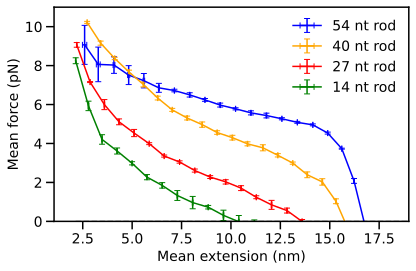

54 nt rod: area under positive mean trajectory = 83.5329 pN*nm (10^-21 J) -> 12.022832 kcal/mol
40 nt rod: area under positive mean trajectory = 64.7367 pN*nm (10^-21 J) -> 9.317508 kcal/mol
27 nt rod: area under positive mean trajectory = 36.4828 pN*nm (10^-21 J) -> 5.250946 kcal/mol
14 nt rod: area under positive mean trajectory = 20.4012 pN*nm (10^-21 J) -> 2.936334 kcal/mol


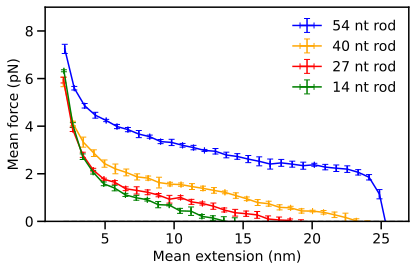

54 nt rod: area under positive mean trajectory = 71.1595 pN*nm (10^-21 J) -> 10.241933 kcal/mol
40 nt rod: area under positive mean trajectory = 30.9944 pN*nm (10^-21 J) -> 4.460994 kcal/mol
27 nt rod: area under positive mean trajectory = 19.6150 pN*nm (10^-21 J) -> 2.823170 kcal/mol
14 nt rod: area under positive mean trajectory = 15.1688 pN*nm (10^-21 J) -> 2.183241 kcal/mol


In [11]:
#### Aggregate means/error bars across seeds and reuse for push/pull
from collections import defaultdict
import numpy as np

AVOGADRO = 6.022e23  # molecules per mole
dict_work_done = {}

ROD_CONFIGS = [
    ('full', '54 nt rod', 'blue'),
    ('3qrt', '40 nt rod', 'orange'),
    ('half', '27 nt rod', 'red'),
    ('1qrt', '14 nt rod', 'green'),
]

def aggregate_by_rod(stats_dict, rod_configs, design_keyword=None):
    grouped = {rod: defaultdict(list) for rod, _, _ in rod_configs}
    
    for subfolder_name, files_dict in stats_dict.items():
        subfolder_lower = subfolder_name.lower()
        if design_keyword and design_keyword.lower() not in subfolder_lower:
            continue
        
        for rod_substr, _, _ in rod_configs:
            if rod_substr in subfolder_lower:
                for (K, r0, seed), stats in files_dict.items():
                    grouped[rod_substr][(K, r0)].append(stats)
                break

    aggregated = {}
    for rod_substr, grouped_by_kr0 in grouped.items():
        rod_points = []
        for (K, r0), entries in grouped_by_kr0.items():
            dist_vals = np.array([e['dist_mean'] for e in entries])
            force_vals = np.array([e['F_mean'] for e in entries])
            ddof = 1 if len(entries) > 1 else 0
            rod_points.append({
                'K': K,
                'r0': r0,
                'dist_mean': dist_vals.mean(),
                'F_mean': force_vals.mean(),
                'dist_err': dist_vals.std(ddof=ddof),
                'F_err': force_vals.std(ddof=ddof),
                'n': len(entries),
            })
        aggregated[rod_substr] = sorted(rod_points, key=lambda x: x['dist_mean'])

    return aggregated

def plot_aggregated_rod_curves(
    stats_dict, rod_configs, design_keyword=None, figsize=(6, 4),
    xlim=(None, 18), ylim=(0, 11)
 ):
    aggregated_data = aggregate_by_rod(stats_dict, rod_configs, design_keyword=design_keyword)
    fig, ax = plt.subplots(figsize=figsize)

    all_x = [
        DIST_CONVERSION * point['dist_mean']
        for rod_points in aggregated_data.values()
        for point in rod_points
    ]
    if all_x:
        xmin = xlim[0] if xlim[0] is not None else min(all_x)
        xmax = xlim[1] if xlim[1] is not None else max(all_x)
        ax.hlines(0, xmin=xmin, xmax=xmax, colors='gray', linestyles='dashed', alpha=0.7)

    area_by_rod = {}
    for rod_substr, label, color in rod_configs:
        points = aggregated_data[rod_substr]
        if not points:
            continue

        x = np.array([DIST_CONVERSION * p['dist_mean'] for p in points])
        y = np.array([FORCE_CONVERSION * p['F_mean'] for p in points])
        xerr = np.array([DIST_CONVERSION * p['dist_err'] for p in points])
        yerr = np.array([FORCE_CONVERSION * p['F_err'] for p in points])

        ax.errorbar(
            x, y, xerr=xerr, yerr=yerr, linestyle='-',
            linewidth=1.5, capsize=3, label=label, color=color
        )

        area_by_rod[label] = np.trapezoid(np.maximum(y, 0.0), x) if len(x) > 1 else float('nan')

    ax.set_xlabel(r"Mean extension (nm)")
    ax.set_ylabel(r"Mean force (pN)")
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()

    for label, area in area_by_rod.items():
        kcalpermol = area * 1e-21 * AVOGADRO / 4184
        dict_work_done[(design_keyword, label)] = kcalpermol
        print(f"{label}: area under positive mean trajectory = {area:.4f} pN*nm (10^-21 J) -> {kcalpermol:.6f} kcal/mol")

    return aggregated_data, area_by_rod

# Per-design axis controls
DESIGNS = ("push", "pull")
XLIMS = ((None, 19), (None, 27))
YLIMS = ((0, 11), (0, 9))

# Reuse exact same code for both push and pull with custom axis ranges
for design, xlim, ylim in zip(DESIGNS, XLIMS, YLIMS):
    aggregated_data, area_by_rod = plot_aggregated_rod_curves(
        stats_dict, ROD_CONFIGS, design_keyword=design, xlim=xlim, ylim=ylim
    )

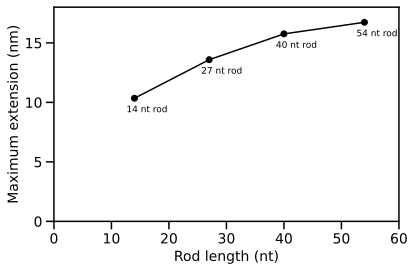

push intercept points: [(14, 10.347120543242001, '14 nt rod'), (27, 13.58732845729456, '27 nt rod'), (40, 15.756987747766647, '40 nt rod'), (54, 16.73111666005712, '54 nt rod')]


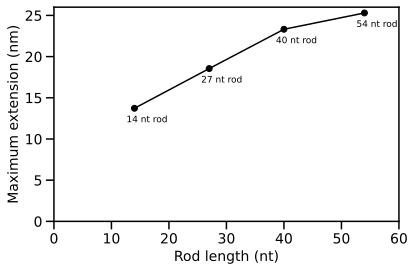

pull intercept points: [(14, 13.727812432923155, '14 nt rod'), (27, 18.547929564221572, '27 nt rod'), (40, 23.31945702414239, '40 nt rod'), (54, 25.30000308622547, '54 nt rod')]


In [14]:
#### MAXIMUM EXTENSION VS ROD LENGTH (push/pull reusable)
import re
import numpy as np
import matplotlib.pyplot as plt

def find_x_intercept(x_vals, y_vals):
    """Find x where y crosses zero using linear interpolation."""
    if len(x_vals) < 2:
        return None

    x_arr = np.asarray(x_vals)
    y_arr = np.asarray(y_vals)
    order = np.argsort(x_arr)
    x_arr = x_arr[order]
    y_arr = y_arr[order]

    for i in range(len(y_arr) - 1):
        y0, y1 = y_arr[i], y_arr[i + 1]
        x0, x1 = x_arr[i], x_arr[i + 1]

        if y0 == 0:
            return float(x0)
        if y1 == 0:
            return float(x1)
        if y0 * y1 < 0:
            return float(x0 + (0 - y0) * (x1 - x0) / (y1 - y0))
    return None

def max_extension_by_rod(stats_dict, rod_configs, design_keyword=None):
    aggregated_data = aggregate_by_rod(stats_dict, rod_configs, design_keyword=design_keyword)
    points = []

    for rod_substr, label, _ in rod_configs:
        agg = aggregated_data.get(rod_substr, [])
        if not agg:
            continue

        x = [DIST_CONVERSION * d['dist_mean'] for d in agg]
        y = [FORCE_CONVERSION * d['F_mean'] for d in agg]
        x0 = find_x_intercept(x, y)
        if x0 is None:
            continue

        match = re.search(r"(\d+)", label)
        if not match:
            continue

        points.append((int(match.group(1)), x0, label))

    points.sort(key=lambda t: t[0])
    return points

def plot_max_extension_vs_rod(stats_dict, rod_configs, design_keyword=None, xlim=(0, 60), ylim=(0, 18), figsize=(6, 4)):
    points = max_extension_by_rod(stats_dict, rod_configs, design_keyword=design_keyword)
    if not points:
        print(f"No intercept points found for design='{design_keyword}'")
        return []

    rod_lengths, x_intercepts, labels = zip(*points)

    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(rod_lengths, x_intercepts, marker='o', markersize=6, color="black", linewidth=1.5)
    for rl, xi, lab in zip(rod_lengths, x_intercepts, labels):
        ax.annotate(lab, (rl, xi), textcoords="offset points", xytext=(-8, -14), fontsize=9)

    ax.set_xlabel("Rod length (nt)")
    ax.set_ylabel(r"Maximum extension (nm)")
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    plt.tight_layout()
    plt.show()

    return points

# Per-design axis controls
DESIGNS_INTERCEPT = ("push", "pull")
XLIMS_INTERCEPT = ((0, 60), (0, 60))
YLIMS_INTERCEPT = ((0, 18), (0, 26))

# Reuse exact same code for both push and pull with custom axis ranges
for design, xlim, ylim in zip(DESIGNS_INTERCEPT, XLIMS_INTERCEPT, YLIMS_INTERCEPT):
    intercept_points = plot_max_extension_vs_rod(
        stats_dict, ROD_CONFIGS, design_keyword=design, xlim=xlim, ylim=ylim
    )
    print(f"{design} intercept points: {intercept_points}")

Text(0, 0.5, 'Work done (kcal mol$^{-1}$)')

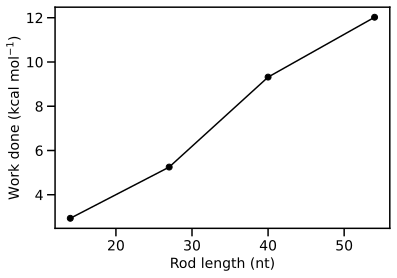

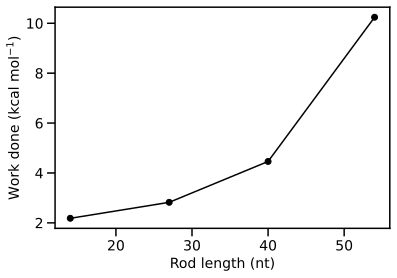

In [13]:
#### PLOTS OF WORK DONE VS ROD LENGTH
x_vals = [54, 40, 27, 14]
y_vals_push = [dict_work_done[(key)] for key in [('push', '54 nt rod'),
                                                 ('push', '40 nt rod'),
                                                 ('push', '27 nt rod'),
                                                 ('push', '14 nt rod')]]
y_vals_pull = [dict_work_done[(key)] for key in [('pull', '54 nt rod'),
                                                 ('pull', '40 nt rod'),
                                                 ('pull', '27 nt rod'),
                                                 ('pull', '14 nt rod')]]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(x_vals, y_vals_push, marker='o', markersize=6,
        color="black", linewidth=1.5)
ax.set_xlabel("Rod length (nt)")
ax.set_ylabel("Work done (kcal mol$^{-1}$)")
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(x_vals, y_vals_pull, marker='o', markersize=6,
        color="black", linewidth=1.5)
ax.set_xlabel("Rod length (nt)")
ax.set_ylabel("Work done (kcal mol$^{-1}$)")